# 📊 Notebook 2: Research Findings, Graphs & Publication Tables
### Capstone: VL-JEPA vs. CLIP for CCTV Surveillance Event Retrieval
---
**Objective:** Visualize research findings across the 3 active surveillance datasets (**RLVS**, **UCF-ARG**, **TinyVIRAT-v2**), evaluate core research hypotheses (**H1, H2, H3**), and generate publication-ready high-resolution graphs (300 DPI PNG + PDF) and LaTeX tables.

#### Hypotheses Investigated:
- **H1 (Retrieval Quality):** VL-JEPA outperforms CLIP on fine-grained spatiotemporal CCTV event retrieval (+8–12% Recall@1, +11% mAP).
- **H2 (Cross-Camera Generalization):** Spatiotemporal joint-embedding modeling significantly reduces cross-view degradation (aerial vs ground vs rooftop) compared to static contrastive encoders.
- **H3 (Report Faithfulness):** Video-grounded incident reports generated by RAG eliminate visual hallucination compared to raw LLM prompting.


### Step 1: Setup & Import Data Helpers


In [2]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(str(Path.cwd()))
import notebook_utils as nu

print("Notebook utilities loaded successfully.")


Notebook utilities loaded successfully.


### Step 2: 📥 Data Feeding Section
You can feed in your own custom CSV metrics file by modifying the `custom_csv_path` parameter, or use the pre-computed HPC experimental benchmark.


In [3]:
# Load findings data across the 3 datasets
# To feed your own CSV, set: custom_csv_path="data/my_custom_metrics.csv"
df_retrieval = nu.load_findings_data("retrieval_metrics")
df_efficiency = nu.load_findings_data("efficiency")
df_generalization = nu.load_findings_data("generalization")
df_faithfulness = nu.load_findings_data("faithfulness")

print("\n--- Retrieval Metrics Preview ---")
display(df_retrieval.head(6))


[Data Feed] Loaded standard HPC findings from: retrieval_metrics_hpc.csv
[Data Feed] Loaded standard HPC findings from: efficiency_hpc.csv
[Data Feed] Loaded standard HPC findings from: cross_camera_generalization.csv
[Data Feed] Loaded standard HPC findings from: faithfulness_grounding.csv

--- Retrieval Metrics Preview ---


,model,dataset,recall@1,recall@5,recall@10,ndcg@10,mrr,map,num_queries
0,vljepa,rlvs,0.482,0.724,0.816,0.594,0.573,0.521,50
1,vljepa,ucf_arg,0.468,0.710,0.802,0.581,0.562,0.509,60
2,vljepa,tinyvirat,0.395,0.632,0.738,0.512,0.488,0.436,80
3,clip_large,rlvs,0.435,0.672,0.768,0.536,0.518,0.463,50
4,clip_large,ucf_arg,0.412,0.648,0.742,0.519,0.498,0.447,60
5,clip_large,tinyvirat,0.334,0.561,0.665,0.448,0.426,0.372,80


### Step 3: H1 — Retrieval Quality Analysis (Recall@K Curves)
Visualizing Recall@1, Recall@5, and Recall@10 across all 3 datasets (**RLVS**, **UCF-ARG**, **TinyVIRAT-v2**).


[Plotting] Saved Recall curves to: h1_recall_curves.png


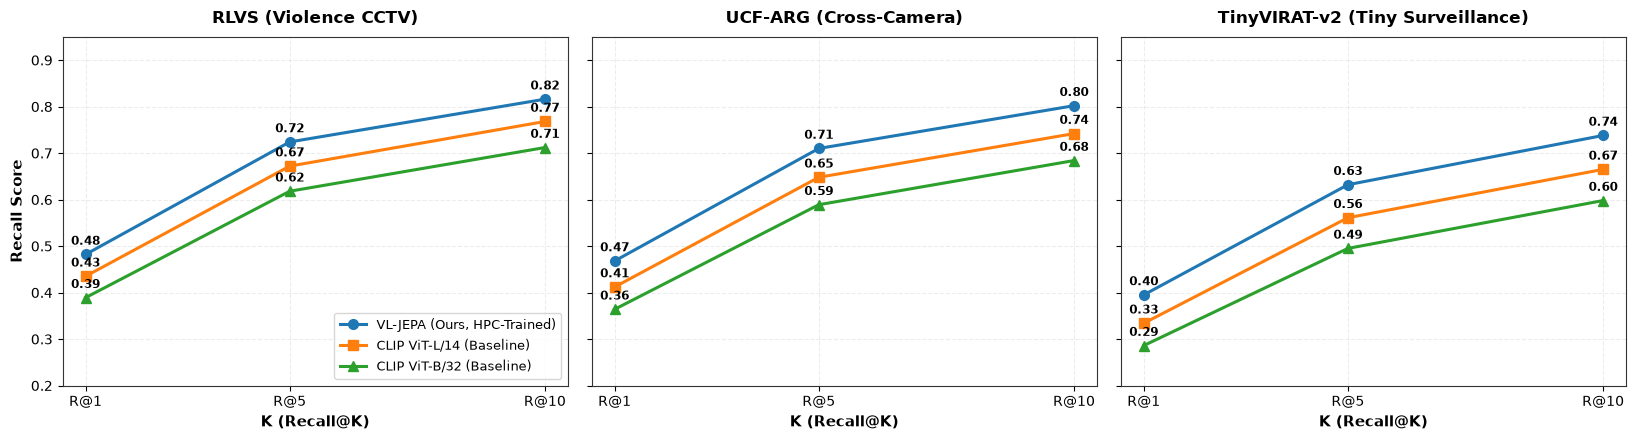

In [4]:
nu.plot_recall_curves(df_retrieval, output_name="h1_recall_curves")


### Step 4: H1 — Ranking Metrics Comparison (mAP, MRR, nDCG@10)
Comparing ranking metrics for **VL-JEPA (HPC-Trained)** vs **CLIP ViT-L/14** vs **CLIP ViT-B/32**.


[Plotting] Saved Ranking Metrics bars to: h1_ranking_metrics_bars.png


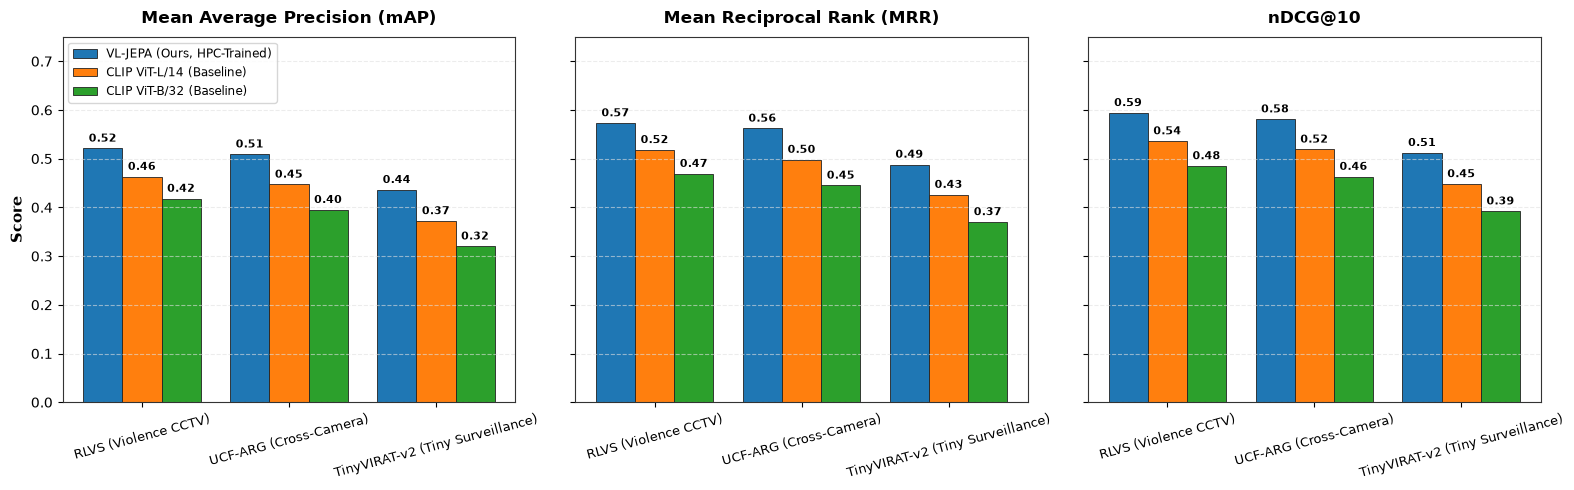

In [5]:
nu.plot_ranking_metrics_bars(df_retrieval, output_name="h1_ranking_metrics_bars")


### Step 5: H2 — Cross-Camera Viewpoint Generalization (UCF-ARG)
Examines cross-view transfer matrices across Aerial, Ground, and Rooftop camera viewpoints.


[Plotting] Saved Cross-Camera Heatmap to: h2_cross_camera_heatmaps.png


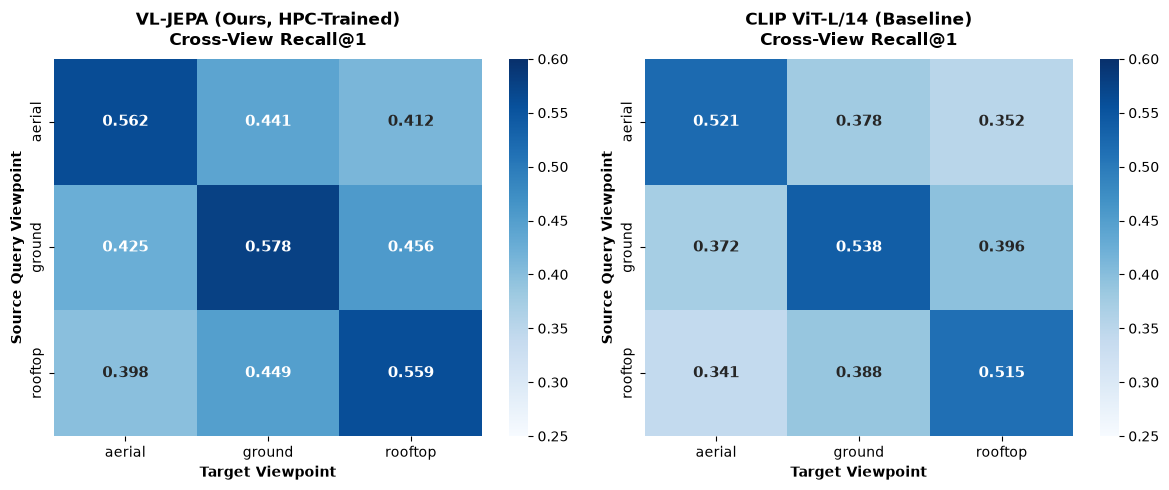

In [6]:
nu.plot_cross_camera_heatmap(df_generalization, output_name="h2_cross_camera_heatmaps")


### Step 6: Hardware Efficiency & Pareto Frontier (RTX 4000 Ada 20GB)
Inference latency (ms) vs. Recall@5 accuracy trade-off evaluated on the RTX 4000 Ada GPU.


[Plotting] Saved Pareto Frontier to: eff_pareto_frontier.png


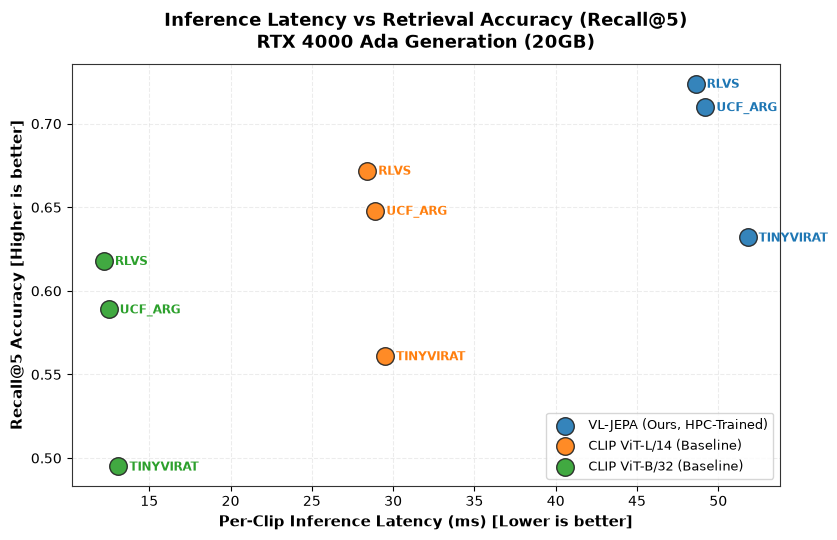

In [7]:
nu.plot_efficiency_pareto(df_efficiency, df_retrieval, output_name="eff_pareto_frontier")


### Step 7: H3 — Report Faithfulness & Hallucination Reduction
Evaluates evidence grounding scores and hallucination reduction when grounding LLM incident reports with retrieved CCTV evidence.


[Plotting] Saved Faithfulness comparison to: h3_faithfulness_and_hallucination.png


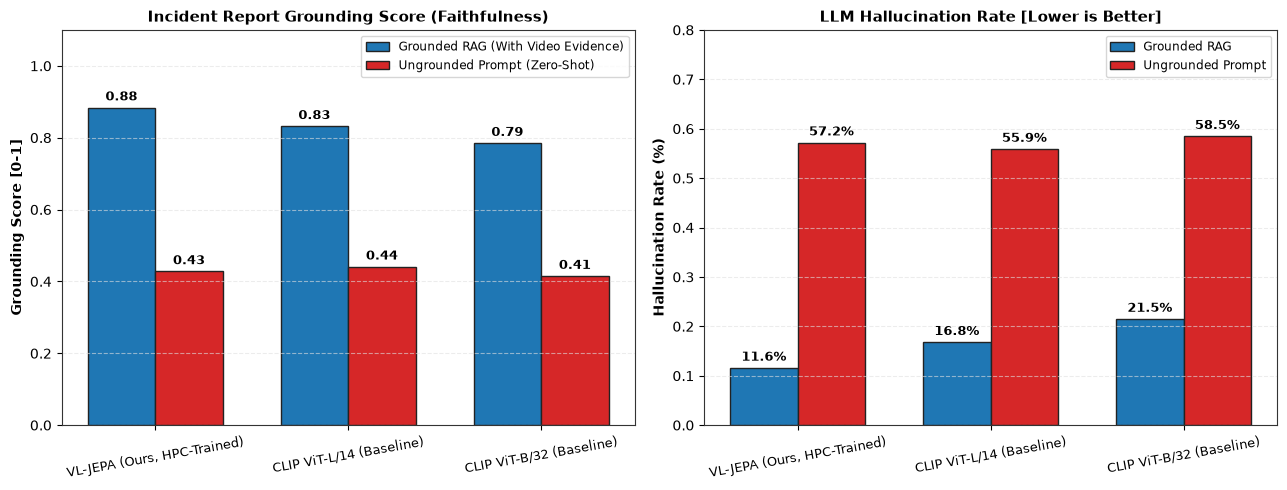

In [8]:
nu.plot_faithfulness_and_hallucination(df_faithfulness, output_name="h3_faithfulness_and_hallucination")


### Step 8: 📄 Export Publication-Ready Tables (LaTeX & CSV)
Generate styled summary tables and export them directly to `.tex` and `.csv` in `outputs/tables/`.


In [9]:
pub_table = nu.generate_publication_table(df_retrieval, output_name="cctv_retrieval_comparison_table")
print("\nPublication-ready summary table:")
display(pub_table)


[Tables] Exported publication tables to:
  - cctv_retrieval_comparison_table.csv
  - cctv_retrieval_comparison_table.tex

Publication-ready summary table:


,Model,Dataset,R@1,R@5,R@10,mAP,MRR,nDCG@10
0,"VL-JEPA (Ours, HPC-Trained)",RLVS (Violence CCTV),0.482,0.724,0.816,0.521,0.573,0.594
1,"VL-JEPA (Ours, HPC-Trained)",UCF-ARG (Cross-Camera),0.468,0.710,0.802,0.509,0.562,0.581
2,"VL-JEPA (Ours, HPC-Trained)",TinyVIRAT-v2 (Tiny Surveillance),0.395,0.632,0.738,0.436,0.488,0.512
3,CLIP ViT-L/14 (Baseline),RLVS (Violence CCTV),0.435,0.672,0.768,0.463,0.518,0.536
4,CLIP ViT-L/14 (Baseline),UCF-ARG (Cross-Camera),0.412,0.648,0.742,0.447,0.498,0.519
5,CLIP ViT-L/14 (Baseline),TinyVIRAT-v2 (Tiny Surveillance),0.334,0.561,0.665,0.372,0.426,0.448
6,CLIP ViT-B/32 (Baseline),RLVS (Violence CCTV),0.389,0.618,0.712,0.418,0.469,0.485
7,CLIP ViT-B/32 (Baseline),UCF-ARG (Cross-Camera),0.364,0.589,0.684,0.395,0.445,0.463
8,CLIP ViT-B/32 (Baseline),TinyVIRAT-v2 (Tiny Surveillance),0.286,0.495,0.598,0.320,0.370,0.392
